In [ ]:
#Imports
import os
import mne
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, ShuffleSplit

from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

mne.set_log_level("WARNING")


### Constants and model setup
Signals are sampled at $f_s = 250\,\text{Hz}$ from 8 channels: C4, C3, Cz, Fz, PO7, Pz, PO8, Oz. `bandpass` lists 29 one-hertz bands $(i, i+1)\,\text{Hz}$ for $i = 1, \dots, 29$, so each band can be scored separately.

Two classifiers are defined:
- `clf` (CSP + LDA):
  - CSP learns 4 spatial filters $w_i$ from Ledoit-Wolf-regularised covariances. Each epoch $X$ becomes 4 features $\log\,\text{var}(w_i^\top X)$.
  - LDA fits a linear decision boundary on those 4 features.
- `model` (Riemannian): each epoch becomes a covariance matrix (Ledoit-Wolf shrinkage), which is projected onto the Riemannian tangent space, standardised, and classified by logistic regression.

Accuracy is estimated with `ShuffleSplit`: 10 random splits, each using 80% of the epochs for training and 20% for testing. `random_state=67` makes the splits reproducible.

`mark` lists the cue markers to read: `move` and `rest` for training files (`target = 0`), `cue_start` for test files (`target = 1`).

In [ ]:
#Variable & Constant
result = []
SFREQ = 250 #Frequency of the eeg
ch_names = ['C4', 'C3', 'Cz','Fz','PO7','Pz','PO8','Oz'] #Channels used in the eeg
bandpass = [(i,i+1) for i in range(1,30)]
#bandpass = [(7,12),(18,24)]
cv = ShuffleSplit(test_size=0.2,random_state=67)
lda = LDA()
csp = CSP(n_components=4, reg="ledoit_wolf", log=True, norm_trace=False)
clf = Pipeline([("CSP",csp),("LDA",lda)])
model = make_pipeline(
    Covariances(estimator="lwf"),
    TangentSpace(metric="riemann"),
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)
mark = [["move","rest"],["cue_start"]]

### Load, filter, and separate into epochs
`convertRaw(PATH, target)` reads one CSV file and returns `(epochs, labels)`. `target` is 0 for a training file and 1 for a test file.
1. The channels in `ch_names` form an array of shape $8 \times T$, where $T$ is the number of samples in the file.
2. Each row whose `Marker_val` is a cue marker (see `mark`) becomes an annotation at time $\text{row index} / f_s$ seconds.
3. For each band in `bandpass`, a copy of the raw data is band-pass filtered and cut into epochs covering $t \in [0.5, 4.5]\,\text{s}$ after each cue. The first 0.5 s after the cue is skipped to avoid the reaction delay. No baseline correction is applied.

Returns:
- `epochs`: a list with one `Epochs` object per band. Each holds an array of shape $n_\text{epochs} \times 8 \times 1001$. The 1001 samples are 4 s at 250 Hz plus one, because both ends of the window are included.
- `labels`: the integer event code of each epoch, taken from the first band's epochs (all bands have the same events). Test files have a single marker type, so their labels are not used.

In [34]:
def convertRaw(PATH,target):
    #0-> train 1->test
    df = pd.read_csv(PATH)
    data = df[ch_names].to_numpy().T
    info = mne.create_info(ch_names=ch_names,sfreq=SFREQ,ch_types="eeg")
    #Converting marker to annotation
    markers =df["Marker_val"]
    cue_indices = df.index[markers.isin(mark[target])].tolist() #Get index of when move and rest is happening
    onset = []
    duration = []
    description = []
    for label_idx in cue_indices:
        label_str = markers.loc[label_idx]
        start_second = label_idx/SFREQ
        onset.append(start_second)
        description.append(label_str)
    anno = mne.Annotations(onset=onset,duration=0,description=description) 
    raw = mne.io.RawArray(data,info)
    raw.set_annotations(anno)
    raw.set_montage("colin27_1005")
    epochs = []
    for low,high in bandpass:
        raw_band = raw.copy().filter(l_freq=low,h_freq=high)
        epoch = mne.Epochs(
            raw_band,
            event_id=mark[target],
            tmin = 0.5,
            tmax = 4.5,
            proj=True,
            baseline=None,
            preload=True,
        )
        epoch.set_annotations(None)  
        epochs.append(epoch)
    labels = epochs[0].events[:,2]
    return(epochs,labels)

### Load one subject
Builds the file paths for one subject (up to three training runs in `Data/Training Set/` and one test file in `Data/Single subject test set/`). A missing training run prints a message. `convertRaw` is then called on each file to produce:
- `train_list`: one entry per training run, each a list of per-band `Epochs`. For subject 1 the runs contain 50, 50 and 10 epochs, each $8 \times 1001$.
- `labels`: the event codes of all training epochs, in run order (110 for subject 1).
- `epoch_train`: one `Epochs` object per band, with the training runs concatenated (110 epochs each for subject 1).
- `epoch_test`: one `Epochs` object per band from the test file. These are unlabelled, with 40 epochs for subject 1.

In [24]:
subject = 1
train_path = []
for i in range(1,4):
    if os.path.exists(f"Data/Training Set/S{"0"*(2-int(math.log(subject,10)))+str(subject)}-00{i}_eeg.csv"):
        train_path.append(f"Data/Training Set/S{"0"*(2-int(math.log(subject,10)))+str(subject)}-00{i}_eeg.csv")
    else:
        print(f"Subject {subject} trial {i} missing")
if len(train_path) != 0:
    test_path = f"Data/Single subject test set/S{"0"*(2-int(math.log(subject,10)))+str(subject)}_test.csv"
else:
    print("No files")
train_list = [] 
labels = []
for i in range(3):
    e, l = convertRaw(train_path[i],0)
    train_list.append(e)
    labels.extend(l)
epoch_train = []
for i in range(len(bandpass)):
    epoch_train.append(mne.concatenate_epochs([train[i] for train in train_list]))
epoch_test = convertRaw(test_path,1)[0]


### Fit, predict, and save
For each band $b$:
1. Estimate accuracy by cross-validation on the training epochs, for both CSP + LDA (`clf`, stored in `Y`) and the Riemannian model (`model`, stored in `Y2`). Each value is the mean over the 10 splits.
2. Fit CSP + LDA on all training epochs of that band.
3. Predict class probabilities $p_b$ for the test epochs.

The Riemannian model is only cross-validated, not used for prediction. The probabilities are averaged across the $B$ bands with equal weight, $\bar{p} = \frac{1}{B}\sum_{b=1}^{B} p_b$, and each test epoch gets the class with the larger $\bar{p}$: column 0 is `move`, column 1 is `rest`.

The predictions are saved to `train_result.csv` with the columns `ID` and `TARGET`. The row index is also written, so the file has an extra unnamed first column. The plot shows cross-validation accuracy per band for both classifiers; band number $i$ covers $(i, i+1)\,\text{Hz}$.

['rest' 'move' 'move' 'move' 'rest' 'move' 'move' 'move' 'move' 'move'
 'move' 'move' 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'move'
 'rest' 'move' 'move' 'move' 'move' 'rest' 'move' 'move' 'rest' 'move'
 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'rest' 'move' 'move']


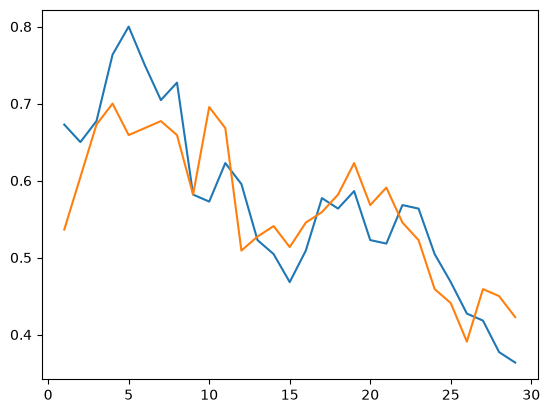

In [30]:
prob = []
Y = []
Y2 = []
for i in range(len(bandpass)):
    scores = cross_val_score(clf, epoch_train[i].get_data(), labels, cv=cv,)
    scores2 = cross_val_score(model, epoch_train[i].get_data(), labels, cv=cv,)
    Y.append(np.mean(scores))
    Y2.append(np.mean(scores2))
    clf.fit(epoch_train[i].get_data(),labels)
    prob.append(clf.predict_proba(epoch_test[i].get_data()))
pred = np.argmax(np.array(prob).mean(0),axis=1)
target = np.array(["move", "rest"])[pred]
dataframe = []
for i in range(len(target)):
    dataframe.append({"ID":i,"TARGET":target[i]})
pd.DataFrame(dataframe).to_csv("train_result.csv",index=True)
print(target)
plt.plot(range(1,len(Y)+1),Y)
plt.plot(range(1,len(Y2)+1),Y2)
plt.show()

['rest' 'move' 'move' 'move' 'rest' 'move' 'move' 'move' 'move' 'move'
 'move' 'move' 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'move'
 'rest' 'move' 'move' 'move' 'move' 'rest' 'move' 'move' 'rest' 'move'
 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'rest' 'move' 'move']


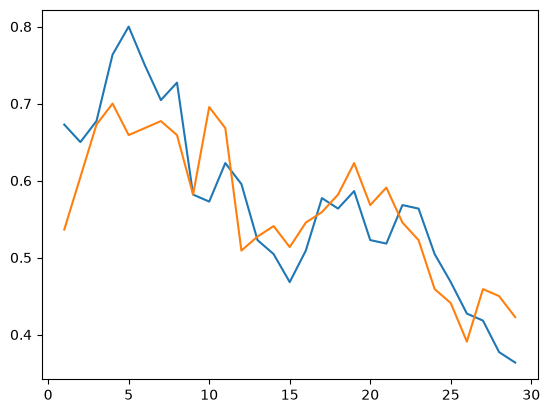

['rest' 'move' 'move' 'move' 'rest' 'move' 'move' 'move' 'move' 'move'
 'move' 'move' 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'move'
 'rest' 'move' 'move' 'move' 'move' 'rest' 'move' 'move' 'rest' 'move'
 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'rest' 'move' 'move']


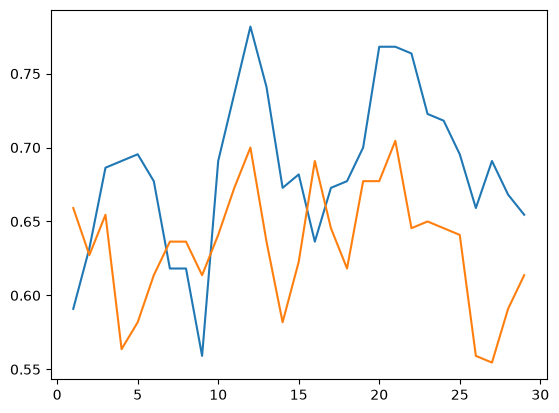

['rest' 'move' 'move' 'move' 'rest' 'move' 'move' 'move' 'move' 'move'
 'move' 'move' 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'move'
 'rest' 'move' 'move' 'move' 'move' 'rest' 'move' 'move' 'rest' 'move'
 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'rest' 'move' 'move']


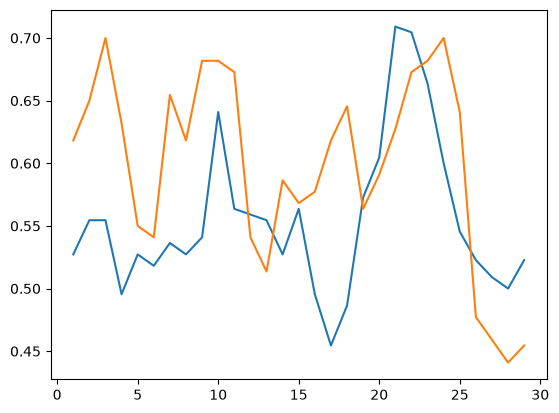

['rest' 'move' 'move' 'move' 'rest' 'move' 'move' 'move' 'move' 'move'
 'move' 'move' 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'move'
 'rest' 'move' 'move' 'move' 'move' 'rest' 'move' 'move' 'rest' 'move'
 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'rest' 'move' 'move']


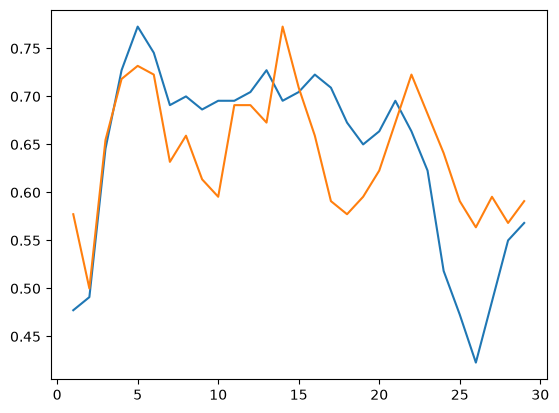

['rest' 'move' 'move' 'move' 'rest' 'move' 'move' 'move' 'move' 'move'
 'move' 'move' 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'move'
 'rest' 'move' 'move' 'move' 'move' 'rest' 'move' 'move' 'rest' 'move'
 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'rest' 'move' 'move']


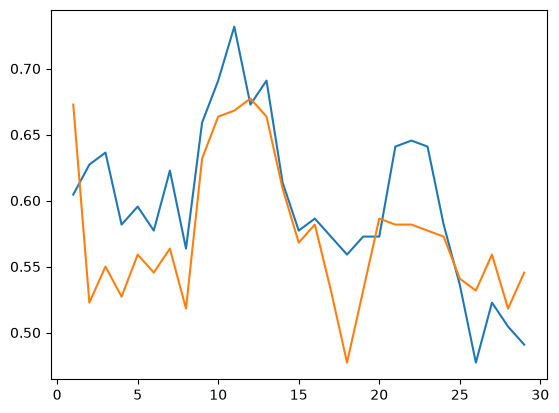

['rest' 'move' 'move' 'move' 'rest' 'move' 'move' 'move' 'move' 'move'
 'move' 'move' 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'move'
 'rest' 'move' 'move' 'move' 'move' 'rest' 'move' 'move' 'rest' 'move'
 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'rest' 'move' 'move']


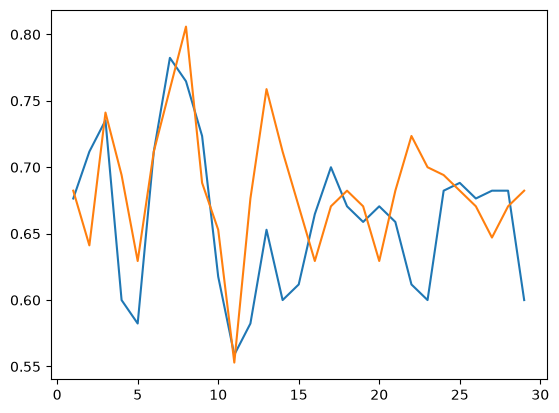

Subject 7 trial 2 missing
['rest' 'move' 'move' 'move' 'rest' 'move' 'move' 'move' 'move' 'move'
 'move' 'move' 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'move'
 'rest' 'move' 'move' 'move' 'move' 'rest' 'move' 'move' 'rest' 'move'
 'move' 'move' 'move' 'move' 'move' 'rest' 'move' 'rest' 'move' 'move']


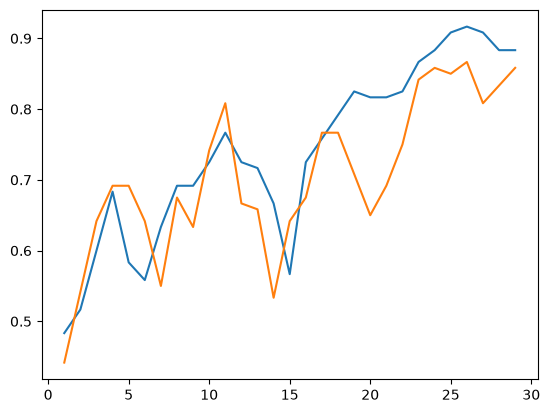

Subject 8 trial 1 missing
Subject 8 trial 2 missing
Subject 8 trial 3 missing
No files


C:\Users\Leo\AppData\Local\Temp\ipykernel_25660\1588176716.py:3: DtypeWarning: Columns (9: Marker_val) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(PATH)


KeyboardInterrupt: 

In [35]:
for subject in range(1,21):
    train_path = []
    for i in range(1,4):
        if os.path.exists(f"Data/Training Set/S{"0"*(2-int(math.log(subject,10)))+str(subject)}-00{i}_eeg.csv"):
            train_path.append(f"Data/Training Set/S{"0"*(2-int(math.log(subject,10)))+str(subject)}-00{i}_eeg.csv")
        else:
            print(f"Subject {subject} trial {i} missing")
    if len(train_path) != 0:
        test_path = f"Data/Single subject test set/S{"0"*(2-int(math.log(subject,10)))+str(subject)}_test.csv"
    else:
        print("No files")
        continue
    train_list = [] 
    labels = []
    for i in range(3):
        try:
            e, l = convertRaw(train_path[i],0)
        except:
            continue
        train_list.append(e)
        labels.extend(l)
    epoch_train = []
    for i in range(len(bandpass)):
        epoch_train.append(mne.concatenate_epochs([train[i] for train in train_list]))
    epoch_test = convertRaw(test_path,1)[0]
    prob = []
    Y = []
    Y2 = []
    for i in range(len(bandpass)):
        scores = cross_val_score(clf, epoch_train[i].get_data(), labels, cv=cv,)
        scores2 = cross_val_score(model, epoch_train[i].get_data(), labels, cv=cv,)
        Y.append(np.mean(scores))
        Y2.append(np.mean(scores2))
    print(target)
    plt.plot(range(1,len(Y)+1),Y)
    plt.plot(range(1,len(Y2)+1),Y2)
    plt.show()